# 02 · Target, split and baselines

**Target** (`src/data/targets.py`): at a prediction point ("anchor", one every 100 m after the first 1 km of a trip
segment), predict the consumption rate over the **next N = 5 km**, in %SoC per km. Distance-to-empty follows as
`DTE = (SoC − 8 %) / rate`. No trip reaches empty, so "actual DTE" means *range if the next 5 km's consumption continued*.

**Split** (`src/data/splits.py`): by **day**, stratified by **season**. 7 days are held out as the test set and are
not used in this notebook. The remaining days form 5 cross-validation folds.

**Baselines** (`src/models/baselines.py`): (a) global average rate from the training folds; (b) this trip's average so far.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data.splits import load_splits
from src.data.targets import build_anchors
from src.evaluate import implied_dte
from src.models.baselines import GlobalAverage, TripSoFar
from src.models.run_baselines import cv_baselines, pooled

FIG_DIR = ROOT / "figures" / "baselines"; FIG_DIR.mkdir(parents=True, exist_ok=True)
SERIES_COLOR = {"A": "#2a78d6", "B": "#eb6834"}; SERIES_LABEL = {"A": "A · summer", "B": "B · winter"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "text.color": "#0b0b0b", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "figure.dpi": 110,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
})

clean = pd.read_parquet(ROOT / "data" / "processed" / "trips_clean.parquet")
splits = load_splits()
anchors = build_anchors(clean).merge(splits[["trip_id", "split", "fold", "day"]], on="trip_id")
cv = anchors[anchors.split == "cv"]
print(f"{len(anchors):,} anchors from {anchors.trip_id.nunique()} trips "
      f"(trips too short for 1 km history + 5 km horizon: {sorted(set(clean.trip_id) - set(anchors.trip_id))})")

9,284 anchors from 66 trips (trips too short for 1 km history + 5 km horizon: ['TripA13', 'TripA14', 'TripB13', 'TripB34'])


## The split

In [2]:
tab = anchors.assign(group=np.where(anchors.split == "test", "test", "fold " + anchors.fold.astype(str)))
summary = tab.groupby("group").agg(days=("day", "nunique"), trips=("trip_id", "nunique"), anchors=("row", "size"))
summary["summer trips"] = tab[tab.series == "A"].groupby("group").trip_id.nunique()
summary["winter trips"] = tab[tab.series == "B"].groupby("group").trip_id.nunique()
summary

,days,trips,anchors,summer trips,winter trips
group,,,,,
fold 0,4,10,1322,5,5
fold 1,5,10,955,5,5
fold 2,6,11,1138,6,5
fold 3,6,11,1518,5,6
fold 4,7,11,2613,5,6
test,6,13,1738,4,9


## The target in the CV data

Rates below are what the models must predict. Note the spread of "actual DTE": a 5 km stretch at a low rate implies a
very long range, which is why errors in km are largest when consumption is low.

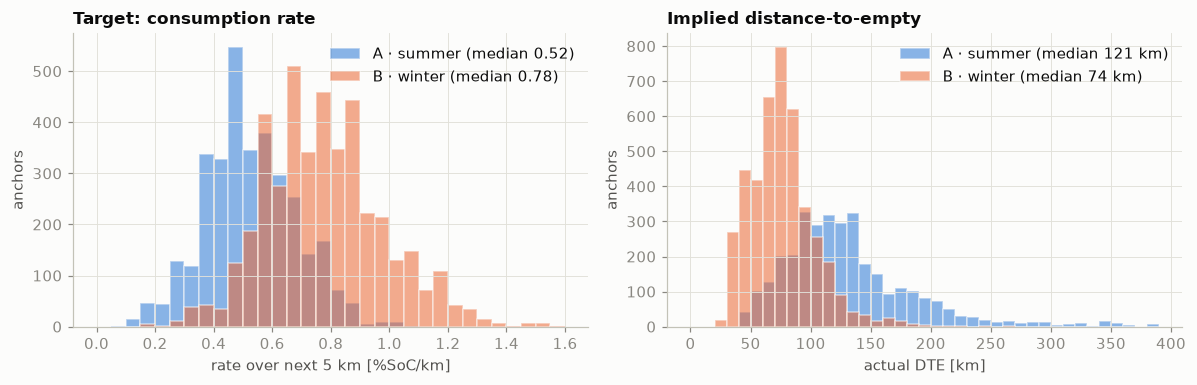

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for s in ["A", "B"]:
    sub = cv[cv.series == s]
    axes[0].hist(sub.rate_next, bins=np.arange(0, 1.65, 0.05), alpha=0.55, color=SERIES_COLOR[s],
                 edgecolor="#fcfcfb", label=f"{SERIES_LABEL[s]} (median {sub.rate_next.median():.2f})")
    axes[1].hist(sub.dte_true_km, bins=np.arange(0, 400, 10), alpha=0.55, color=SERIES_COLOR[s],
                 edgecolor="#fcfcfb", label=f"{SERIES_LABEL[s]} (median {sub.dte_true_km.median():.0f} km)")
axes[0].set_xlabel("rate over next 5 km [%SoC/km]"); axes[0].set_title("Target: consumption rate")
axes[1].set_xlabel("actual DTE [km]"); axes[1].set_title("Implied distance-to-empty")
for ax in axes: ax.set_ylabel("anchors"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "target_distribution.png", bbox_inches="tight"); plt.show()

## Baseline results (5-fold CV, grouped by day)

Each fold's baselines are fit on the other four folds. The test set is evaluated once for all models together at the
end of Phase 3. `pooled` = metrics over all validation anchors together; `mean ± std` = across the 5 folds.

In [4]:
per_fold = cv_baselines(clean, anchors, splits)
summary = per_fold.groupby("model")[["mae_rate", "rmse_rate", "mae_dte_km"]].agg(["mean", "std"])
display(summary.round(3))
display(pooled(clean, anchors, splits).round(3))

mae_rate        rmse_rate        mae_dte_km       
                         mean    std      mean    std       mean    std
model                                                                  
baseline_global_avg     0.183  0.028     0.224  0.031     29.062  6.628
baseline_trip_so_far    0.279  0.047     0.374  0.048     31.343  5.414

,mae_rate,rmse_rate,mae_dte_km,share_floored
baseline_global_avg,0.183,0.226,29.782,0.0
baseline_trip_so_far,0.269,0.367,31.756,0.0


## Why does "trip so far" lose to the global average?

Break the CV errors down by how much of the trip has been driven, and by season.

,abs_err_global_avg,abs_err_trip_so_far,anchors
history,,,
1–2 km,0.179,0.562,530
2–5,0.178,0.370,1536
5–10,0.169,0.267,2213
10–20,0.216,0.177,1745
20+,0.169,0.173,1522


,abs_err_global_avg,abs_err_trip_so_far,bias_global_avg,bias_trip_so_far
series,,,,
A · summer,0.203,0.206,0.180,0.157
B · winter,0.167,0.318,-0.074,0.267


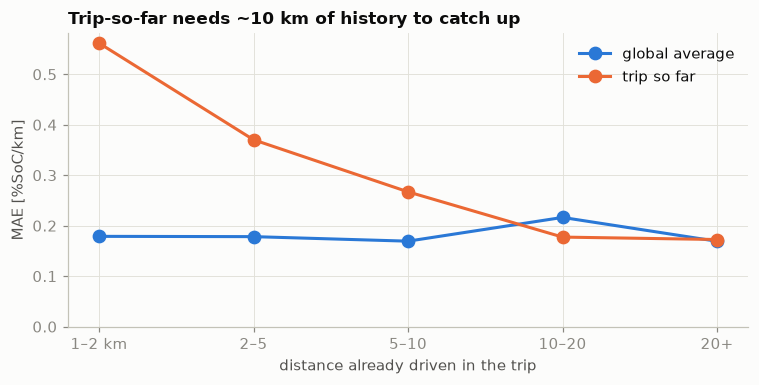

In [5]:
fold_of = splits.set_index("trip_id").fold
preds = []
for f in range(5):
    train = clean[clean.trip_id.map(fold_of).isin(set(range(5)) - {f})]
    val = cv[cv.fold == f]
    preds.append(val.assign(global_avg=GlobalAverage().fit(train).predict(val), trip_so_far=TripSoFar().predict(val)))
p = pd.concat(preds)
for m in ["global_avg", "trip_so_far"]:
    p[f"abs_err_{m}"] = (p[m] - p.rate_next).abs()
    p[f"bias_{m}"] = p[m] - p.rate_next

p["history"] = pd.cut(p.km_in_segment, [1, 2, 5, 10, 20, 70], labels=["1–2 km", "2–5", "5–10", "10–20", "20+"])
by_hist = p.groupby("history", observed=True)[["abs_err_global_avg", "abs_err_trip_so_far"]].mean()
by_hist["anchors"] = p.groupby("history", observed=True).size()
display(by_hist.round(3))
by_season = p.groupby("series")[["abs_err_global_avg", "abs_err_trip_so_far", "bias_global_avg", "bias_trip_so_far"]].mean()
by_season.index = by_season.index.map(SERIES_LABEL)
display(by_season.round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(by_hist))
ax.plot(x, by_hist.abs_err_global_avg, marker="o", ms=8, color="#2a78d6", label="global average")
ax.plot(x, by_hist.abs_err_trip_so_far, marker="o", ms=8, color="#eb6834", label="trip so far")
ax.set_xticks(x); ax.set_xticklabels(by_hist.index.astype(str))
ax.set_xlabel("distance already driven in the trip"); ax.set_ylabel("MAE [%SoC/km]")
ax.set_title("Trip-so-far needs ~10 km of history to catch up"); ax.set_ylim(0, None); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "baseline_error_by_history.png", bbox_inches="tight"); plt.show()

## One validation trip

The longest winter trip in the CV folds (chosen by rule). Left: rate; right: the implied DTE.

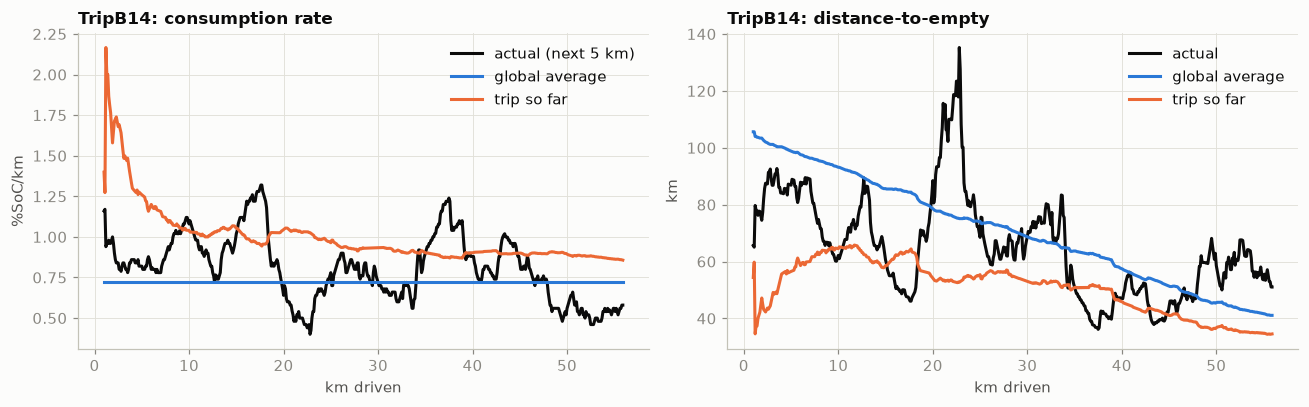

In [6]:
lengths = p.groupby("trip_id").km_in_segment.max()
tid = lengths[p.groupby("trip_id").series.first() == "B"].idxmax()
t = p[p.trip_id == tid]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(t.km_in_segment, t.rate_next, color="#0b0b0b", label="actual (next 5 km)")
axes[0].plot(t.km_in_segment, t.global_avg, color="#2a78d6", label="global average")
axes[0].plot(t.km_in_segment, t.trip_so_far, color="#eb6834", label="trip so far")
axes[0].set_ylabel("%SoC/km"); axes[0].set_title(f"{tid}: consumption rate")
axes[1].plot(t.km_in_segment, t.dte_true_km, color="#0b0b0b", label="actual")
axes[1].plot(t.km_in_segment, implied_dte(t.usable_soc_pct, t.global_avg), color="#2a78d6", label="global average")
axes[1].plot(t.km_in_segment, implied_dte(t.usable_soc_pct, t.trip_so_far), color="#eb6834", label="trip so far")
axes[1].set_ylabel("km"); axes[1].set_title(f"{tid}: distance-to-empty")
for ax in axes: ax.set_xlabel("km driven"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "baselines_one_trip.png", bbox_inches="tight"); plt.show()